# Sentinel Hub API

This notebook is used as an explanation of how to use the basic functionalities of Sentinel Hub for Planet AI objectives.

## 1. Setting the environment
Connect to Google Colab in case you are running your notebook ther.

In [1]:
from google.colab import drive
drive.mount("/content/gdrive")

Mounted at /content/gdrive


Go to the directory where you are going to manage all the data downloaded and outputs obtained from your notebooks

In [2]:
import os
#Path to the directory where to create the folders for storing the data.
inDir = "/content/gdrive/MyDrive/"
os.chdir(inDir)
import sys
#Path for the directory where the utils modules are saved.
modulePaths = "/content/gdrive/MyDrive/"
sys.path.append(modulePaths)

Create a `generalPath` variable for  indicating the folder where to store the data.

In [3]:
generalPath = "./data/"

## 2. Install and import

Install additional libraries to the default installed in your local machine.

In [4]:
!pip install --quiet sentinelhub xarray rioxarray folium h3

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.8/249.8 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.9/61.9 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 49.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.6/137.6 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.2/22.2 MB 71.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 236.0/236.0 kB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 3.8 MB/s eta 0:00:00


Import the necessary libraries for managing `.tif` images, along with other basic libraries for managing files and arrays in Python.

In [5]:
import xarray as xr
import rioxarray as rxr
import folium
from sentinelhub import (MimeType,
                         SentinelHubDownloadClient,
                         SentinelHubRequest,
                         SentinelHubCatalog,
                         bbox_to_dimensions,
                         filter_times,
                         CRS,
                         BBox,
                         DataCollection,
                         SHConfig)
import h3


import numpy as np
import matplotlib.pyplot as plt


import time
import datetime as dt

import os
from pathlib import Path
import pickle

## 3. Location hyperparameters

Let's define a variable with the name we want to give to the location we are interested. This variable is important because your data is going to be saved in a folder named with this location. We are going to observe one reknown big source of methane in Turkmenistan.

In [6]:
locationName = "Bogotá"

Define the geographic variables for requesting the data from the API. We define the latitude and longitude of the center of the image and then a list representing the bbox (bounding box) of the region to be observed in the image. Also, define a tuple for the resolution required in each of the axis.

In [7]:
latit, longit = (4.711 	, -74.0721) #(latitude, longitude)
# bbox geographic coordinates.
bbox = [
    longit-0.03, # west
    latit-0.02, # south
    longit+0.03, # east
    latit+0.02 # north
]

resolution = (30, # meters - latitude
              30) # meters - longitude

Let's previsualize the location we are looking for

In [8]:
m = folium.Map(
    location=[latit, longit],
    zoom_start=13,
    tiles="Esri.WorldImagery"
)

folium.Rectangle(bounds=[[bbox[1], bbox[0]],[bbox[3], bbox[2]]], color='#ff7800', fill=True, fill_color='#ffff00', fill_opacity=0.2).add_to(m)
m

Define the range of dates for downloading the data.

In [ ]:
datesObs = ['2022-11-01','2022-12-01']

## 4. Sentinel Hub API

### 4.1 Basic configurations of the API

Add your cliend ID, client secret and the corresponding URLs for the services to create the respective token and data URL.

In [ ]:
# Copernicus ID crear cuenta para poner el cliente ID y Cliente Secret
config = SHConfig()
config.sh_client_id = 'client_id'
config.sh_client_secret = 'client_secret'
config.sh_token_url = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
config.sh_base_url = "https://sh.dataspace.copernicus.eu"

Create the specifications for the Bbox in terms of the SentinelHub API

In [ ]:
location_bbox = BBox(bbox=bbox, crs=CRS.WGS84)
location_size = bbox_to_dimensions(location_bbox, resolution=resolution)

#4.2 Making a request

Define the product you want to download from the API. The available products are shown [here](https://documentation.dataspace.copernicus.eu/APIs/SentinelHub/Data.html)

In [ ]:
from sentinelhub import DataCollection

def list_available_data_collections():
    """Lists available data collections in Sentinel Hub's DataCollection class."""
    collections = [attr for attr in dir(DataCollection) if not attr.startswith("_")]
    print("Available Data Collections in Sentinel Hub:")
    for collection in collections:
        print(f"- {collection}")

if __name__ == "__main__":
    list_available_data_collections()

Available Data Collections in Sentinel Hub:
- DEM
- DEM_COPERNICUS_30
- DEM_COPERNICUS_90
- DEM_MAPZEN
- HARMONIZED_LANDSAT_SENTINEL
- LANDSAT_ETM_L1
- LANDSAT_ETM_L2
- LANDSAT_MSS_L1
- LANDSAT_OT_L1
- LANDSAT_OT_L2
- LANDSAT_TM_L1
- LANDSAT_TM_L2
- MODIS
- SENTINEL1
- SENTINEL1_EW
- SENTINEL1_EW_ASC
- SENTINEL1_EW_DES
- SENTINEL1_EW_SH
- SENTINEL1_EW_SH_ASC
- SENTINEL1_EW_SH_DES
- SENTINEL1_IW
- SENTINEL1_IW_ASC
- SENTINEL1_IW_DES
- SENTINEL2_L1C
- SENTINEL2_L2A
- SENTINEL3_OLCI
- SENTINEL3_SLSTR
- SENTINEL5P


In [ ]:
from sentinelhub import DataCollection

def list_available_data_collections():
    """Lists available data collections in Sentinel Hub's DataCollection class."""
    collections = [attr for attr in dir(DataCollection) if not attr.startswith("_")]
    print("Available Data Collections in Sentinel Hub:")
    for collection in collections:
        print(f"- {collection}")

if __name__ == "__main__":
    list_available_data_collections()

Available Data Collections in Sentinel Hub:
- DEM
- DEM_COPERNICUS_30
- DEM_COPERNICUS_90
- DEM_MAPZEN
- HARMONIZED_LANDSAT_SENTINEL
- LANDSAT_ETM_L1
- LANDSAT_ETM_L2
- LANDSAT_MSS_L1
- LANDSAT_OT_L1
- LANDSAT_OT_L2
- LANDSAT_TM_L1
- LANDSAT_TM_L2
- MODIS
- SENTINEL1
- SENTINEL1_EW
- SENTINEL1_EW_ASC
- SENTINEL1_EW_DES
- SENTINEL1_EW_SH
- SENTINEL1_EW_SH_ASC
- SENTINEL1_EW_SH_DES
- SENTINEL1_IW
- SENTINEL1_IW_ASC
- SENTINEL1_IW_DES
- SENTINEL2_L1C
- SENTINEL2_L2A
- SENTINEL3_OLCI
- SENTINEL3_SLSTR
- SENTINEL5P


In [ ]:
#dataCollection = DataCollection.SENTINEL2_L1C.define_from("s2l1c", service_url=config.sh_base_url)
dataCollection = DataCollection.SENTINEL1_IW.define_from(
                            "s1iw", service_url=config.sh_base_url
                        )

Call the SentinelHub catalog to check the dates of the images available in the interval of dates you defined.

In [ ]:
catalog = SentinelHubCatalog(config=config)
search_iterator = catalog.search(
    dataCollection,
    bbox=location_bbox,
    time=tuple(datesObs),
    # filter="eo:cloud_cover < 5",
    # fields={"include": ["id", "properties.datetime", "properties.eo:cloud_cover"], "exclude": []},
)

In [ ]:
all_timestamps = search_iterator.get_timestamps()
time_difference = dt.timedelta(hours=1)

unique_acquisitions = filter_times(all_timestamps, time_difference)

unique_acquisitions

[datetime.datetime(2022, 11, 9, 10, 43, 27, tzinfo=tzlocal()),
 datetime.datetime(2022, 11, 21, 10, 43, 28, tzinfo=tzlocal())]

Defined an evalscript that specifies the data to be requested. The evalscript in javascript style is explained [here](https://docs.sentinel-hub.com/api/latest/evalscript/v3/).

In [ ]:
bands_evalscript = """
            function setup() {
                return {
                input: ["VV", "VH"],
                output: { bands: 2, sampleType: "FLOAT32"}                  // Refer to Note 1
                }
            }

            function evaluatePixel(sample) {
            return [sample.VV,sample.VH];
            }
            """

Let's define the path for saving the data. The path is designed so that the directory is named after the location name defined at the beginning of the notebook

In [ ]:
folder_out = generalPath + "downloaded/" + locationName + "/"

if not os.path.exists(folder_out):
    os.makedirs(folder_out)

Use the `SentinelHubRequest` function for handling the requests to the Sentinel Hub API. The data requested will be saved in the `folder_out` path.

In [ ]:
def get_request(fixed_time):
    return SentinelHubRequest(
        evalscript=bands_evalscript,
        input_data=[
            SentinelHubRequest.input_data(
                data_collection=dataCollection,
                time_interval=(fixed_time - time_difference, fixed_time+time_difference),
            )
        ],
        responses=[SentinelHubRequest.output_response("default", MimeType.TIFF)],
        bbox=location_bbox,
        size=location_size,
        config=config,
        data_folder=folder_out,
    )
process_requests = []

# create a dictionary of requests
sh_requests = {}
for date in unique_acquisitions:
    str(date)
    sh_requests[str(date)] = get_request(date)

sh_requests

{'2022-11-09 10:43:27+00:00': <sentinelhub.api.process.SentinelHubRequest at 0x7afbfa3970d0>,
 '2022-11-21 10:43:28+00:00': <sentinelhub.api.process.SentinelHubRequest at 0x7afbf9f23110>}

In [ ]:
list_of_requests = [request.download_list[0] for request in sh_requests.values()]

# download data with multiple threads
data = SentinelHubDownloadClient(config=config).download(
    list_of_requests, max_threads=5
)

Rename the downloaded files to their corresponding dates and converting them to `.tif` files.

In [ ]:
def request_output_path(request):
    # Gets the full path to the output from a request
    return Path(request.data_folder, request.get_filename_list()[0])


# Moves and renames the files to the root directory of results
for date, request in sh_requests.items():
    renamed_item = folder_out+str(date)+".tif"
    if not os.path.exists(renamed_item):
        request_output_path(request).rename(renamed_item)

Charge the `.tif` files and store them as xarrays. Concatenate this images through a new dimension indicating time.

In [ ]:
tiff_paths = Path(folder_out).glob("*.tif")

images_ds = []
for path in tiff_paths:
    print(path)
    images_ds.append(rxr.open_rasterio(path))
print(images_ds)

images_ds = xr.concat(images_ds, np.array(unique_acquisitions, dtype=dt.datetime))
images_ds = images_ds.rename({"concat_dim": "t"})

data/downloaded/Bogotá/2022-11-21 10:43:28+00:00.tif


data/downloaded/Bogotá/2022-11-09 10:43:27+00:00.tif


[<xarray.DataArray (band: 2, y: 148, x: 222)> Size: 263kB
[65712 values with dtype=float32]
Coordinates:
  * band         (band) int64 16B 1 2
  * x            (x) float64 2kB -74.1 -74.1 -74.1 ... -74.04 -74.04 -74.04
  * y            (y) float64 1kB 4.731 4.731 4.73 4.73 ... 4.692 4.691 4.691
    spatial_ref  int64 8B 0
Attributes:
    TIFFTAG_XRESOLUTION:     1
    TIFFTAG_YRESOLUTION:     1
    TIFFTAG_RESOLUTIONUNIT:  1 (unitless)
    AREA_OR_POINT:           Area
    scale_factor:            1.0
    add_offset:              0.0, <xarray.DataArray (band: 2, y: 148, x: 222)> Size: 263kB
[65712 values with dtype=float32]
Coordinates:
  * band         (band) int64 16B 1 2
  * x            (x) float64 2kB -74.1 -74.1 -74.1 ... -74.04 -74.04 -74.04
  * y            (y) float64 1kB 4.731 4.731 4.73 4.73 ... 4.692 4.691 4.691
    spatial_ref  int64 8B 0
Attributes:
    TIFFTAG_XRESOLUTION:     1
    TIFFTAG_YRESOLUTION:     1
    TIFFTAG_RESOLUTIONUNIT:  1 (unitless)
    AREA_OR_POINT:  

(148, 222)


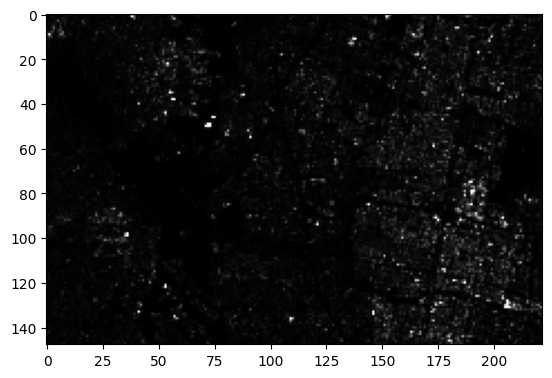

In [ ]:
import matplotlib.colors as colors

img = images_ds[{"t": 1}][0]
print(img.shape)

plt.imshow(img, cmap="gray", vmin = img.min()*3, vmax= img.max()/6)

## 5. Using Uber H3 library.

In [ ]:
images_ds

<xarray.DataArray (t: 2, band: 2, y: 148, x: 222)> Size: 526kB
array([[[[0.19532631, 0.2861919 , 0.28815317, ..., 0.780942  ,
          0.90906495, 1.0319293 ],
         [0.19368252, 0.2552469 , 0.5792956 , ..., 0.53187007,
          0.45935208, 0.5896018 ],
         [0.32098362, 1.0519034 , 0.76385325, ..., 0.9267014 ,
          1.738595  , 1.2635541 ],
         ...,
         [0.15001354, 0.4889983 , 0.22373693, ..., 0.4759595 ,
          0.46083307, 1.4796013 ],
         [0.21162038, 0.37031674, 0.63272494, ..., 0.10972932,
          0.4608085 , 1.2692058 ],
         [0.53943104, 1.5344133 , 0.3839336 , ..., 0.14418127,
          0.3147256 , 0.6698232 ]],

        [[0.04564133, 0.06360804, 0.07673751, ..., 0.1593603 ,
          0.14054807, 0.03918007],
         [0.01412633, 0.03467399, 0.11019615, ..., 0.03841819,
          0.06360126, 0.05977851],
         [0.08990846, 0.05700445, 0.07568712, ..., 0.048159  ,
          0.04397779, 0.09792601],
...
         [0.35056227, 0.26051232, 0.32254153, ..., 0.8663475 ,
          0.45865917, 1.1412268 ],
         [0.33107385, 0.4587178 , 0.49187657, ..., 0.15734039,
          0.1401203 , 0.83239734],
         [0.5129156 , 0.79212475, 0.55615115, ..., 0.09897744,
          0.18017489, 0.36431602]],

        [[0.01926069, 0.13694666, 0.08349252, ..., 0.06692177,
          0.09023625, 0.08354456],
         [0.0272745 , 0.06781638, 0.0510164 , ..., 0.05556029,
          0.04682925, 0.0443315 ],
         [0.02220372, 0.02928055, 0.01811855, ..., 0.0813861 ,
          0.05829629, 0.14948878],
         ...,
         [0.08426946, 0.11013646, 0.06750266, ..., 0.27394176,
          0.06173892, 0.26620403],
         [0.15072767, 0.19410667, 0.15657431, ..., 0.01841681,
          0.1903315 , 0.24561249],
         [0.08759525, 0.18920045, 0.20577523, ..., 0.04406104,
          0.08209755, 0.04569085]]]], dtype=float32)
Coordinates:
  * band         (band) int64 16B 1 2
  * x            (x) float64 2kB -74.1 -74.1 -74.1 ... -74.04 -74.04 -74.04
  * y            (y) float64 1kB 4.731 4.731 4.73 4.73 ... 4.692 4.691 4.691
    spatial_ref  int64 8B 0
  * t            (t) object 16B 2022-11-09T10:43:27+00:00 2022-11-21T10:43:28...
Attributes:
    TIFFTAG_XRESOLUTION:     1
    TIFFTAG_YRESOLUTION:     1
    TIFFTAG_RESOLUTIONUNIT:  1 (unitless)
    AREA_OR_POINT:           Area
    scale_factor:            1.0
    add_offset:              0.0

In [ ]:
# Translate tif to XYZ dataframe
df = (images_ds[{"t": 0}]
      .sel(band=1)
      .to_pandas()
      .stack()
      .reset_index()
      .rename(columns={'x': 'lng', 'y': 'lat', 0: 'elevation'}))

In [ ]:
def plot_scatter(df, metric_col, x='lng', y='lat', marker='.', alpha=1, figsize=(16,12), colormap='viridis', **kwargs):
    df.plot.scatter(x=x, y=y, c=metric_col, title=metric_col
                    , edgecolors='none', colormap=colormap, marker=marker, alpha=alpha, figsize=figsize, **kwargs);
    plt.xticks([], []); plt.yticks([], [])

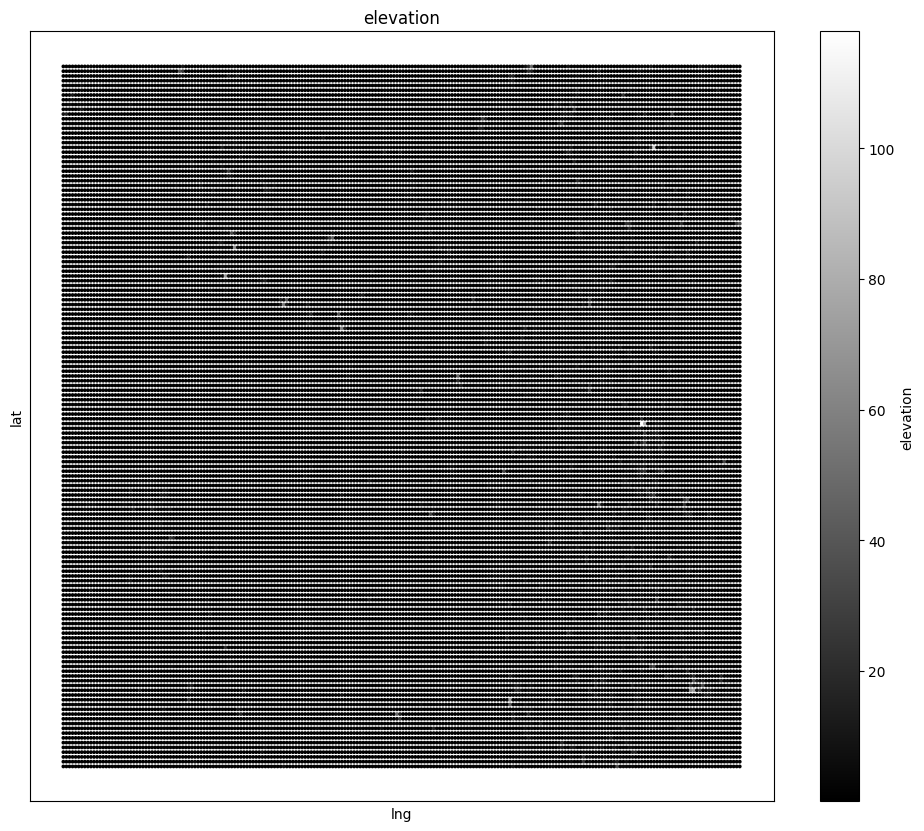

In [ ]:
# Visualize the elevation
plot_scatter(df, metric_col='elevation', marker='.', colormap='gray', figsize = (12,10), s = 30)

In [ ]:

for APERTURE_SIZE in [9,10,11,12,13]:
    hex_col = 'hex'+str(APERTURE_SIZE)

    # find hexs containing the points
    df[hex_col] = df.apply(lambda x: h3.geo_to_h3(x.lat,x.lng,APERTURE_SIZE),1)

    # calculate elevation average per hex
    df_dem = df.groupby(hex_col)['elevation'].mean().to_frame('elevation').reset_index()

    #find center of hex for visualization
    df_dem['lat'] = df_dem[hex_col].apply(lambda x: h3.h3_to_geo(x)[0])
    df_dem['lng'] = df_dem[hex_col].apply(lambda x: h3.h3_to_geo(x)[1])

    # plot the hexes
    plot_scatter(df_dem, metric_col='elevation', marker='o', colormap = "gray", s = 30)
    plt.title('hex-grid: elevation - Aperture size'+str(APERTURE_SIZE));

AttributeError: module 'h3' has no attribute 'geo_to_h3'